# Exploración de datos (EDA) · Hackathon HORSE
### Línea 5 de montaje de motores · Valladolid

Partimos de los datos que deja `limpieza.py` en `Datos_limpios/`. El objetivo de este notebook es **entender cómo se comporta la línea** antes de aplicar los métodos de detección de la máquina crítica:

1. ¿Cuánto produce la línea y en qué se le va el tiempo?
2. ¿Cómo están las máquinas frente a los indicadores de HORSE (disponibilidad, tiempo de ciclo, frecuencia de paradas)?
3. ¿Qué máquinas paran más por sí mismas (TAP)? ¿Es un problema puntual o de siempre?
4. ¿Cómo se reparten las paradas inducidas (SAT y DES) a lo largo de la línea? Ahí está la pista de la máquina crítica.
5. ¿Es siempre la misma máquina la que manda, o cambia de un día a otro?

**Recordatorio de conceptos**

| Sigla | Significado |
|---|---|
| `TBF` | Horas produciendo |
| `TAP` | Parada **propia** (la máquina falla) |
| `DES` | Desabastecimiento: espera piezas de la máquina **anterior** |
| `SAT` | Saturación: no puede soltar la pieza porque la **siguiente** está llena |
| `TAI` | Parada **inducida** = DES + SAT |
| `NAP` / `NPR` | Número de paradas propias / número de piezas |

Cada fila de los datos limpios suma **22 h** (tiempo abierto del día).

## 0. Preparación

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

DATOS = Path("Datos_limpios")
T_ABIERTO = 22.0
ESTADOS = ["TBF", "TAP", "DES", "SAT"]
COLORES = {"TBF": "#4C9F70", "TAP": "#D1495B", "DES": "#EDAE49", "SAT": "#00798C", "T_no_registrado": "#B0B0B0"}
NOMBRES = {"TBF": "Producción (TBF)", "TAP": "Parada propia (TAP)", "DES": "Desabastecimiento (DES)",
           "SAT": "Saturación (SAT)", "T_no_registrado": "No registrado"}

# Referencias de HORSE
TCY_OBJ = 80     # cmin por pieza (1 cmin = 0,6 s)
DP_OBJ = 90      # % disponibilidad

sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams["figure.dpi"] = 110

## 1. Qué datos usamos

Cargamos los datos limpios y las **alertas** de la limpieza. Las alertas nos dicen qué datos no podemos creer, y lo usamos de forma **automática** (sin escribir nombres de máquinas a mano):

- Las máquinas **excluidas** en la limpieza no entran (`incluir_analisis = False`).
- Si una máquina tiene el **sensor de paradas defectuoso**, su TAP no es fiable.
- Si tiene el **contador de piezas defectuoso**, sus piezas no son fiables y no se puede calcular su tiempo de ciclo.

In [2]:
d = pd.read_csv(DATOS / "datos_limpios.csv", keep_default_na=False)
alertas = json.loads((DATOS / "alertas.json").read_text(encoding="utf-8"))
registro = json.loads((DATOS / "registro_limpieza.json").read_text(encoding="utf-8"))

def ops_con(categorias):
    return sorted({a["operacion"] for a in alertas["alertas"] if a["categoria"] in categorias})

TAP_NO_FIABLE = ops_con({"sensor_paradas_defectuoso"})
NPR_NO_FIABLE = ops_con({"contador_piezas_defectuoso", "contador_piezas_excesivo"})
PARALELO = sorted({e["operacion"] for e in registro["entradas"] if e["categoria"] == "posible_paralelo"})

a = d[d.incluir_analisis].copy()
print(f"Periodo: {alertas['periodo']['desde']} a {alertas['periodo']['hasta']} ({alertas['periodo']['dias_productivos']} días productivos)")
print(f"Operaciones en el análisis: {a.Operacion.nunique()}")
print(f"TAP no fiable (sensor de paradas):  {TAP_NO_FIABLE}")
print(f"Piezas no fiables (contador):       {NPR_NO_FIABLE}")
print(f"Posibles puestos en paralelo:       {PARALELO}")

Periodo: S40-D2 a S43-D5 (16 días productivos)
Operaciones en el análisis: 85
TAP no fiable (sensor de paradas):  ['ST2235']
Piezas no fiables (contador):       ['ST-0295', 'ST2235', 'ST_3300']
Posibles puestos en paralelo:       ['ST-2375', 'ST2376']


Las máquinas con TAP no fiable **sí se muestran** en las gráficas generales, pero se marcan y **no cuentan** en los rankings de paradas. Si no, una máquina con un sensor que parpadea saldría como "la que más para" sin serlo.

In [4]:
DIA = ["Week", "Jour"]
a["dia"] = "S" + a.Week.astype(str) + "-D" + a.Jour.astype(str)
dias = a[DIA + ["dia"]].drop_duplicates().sort_values(DIA).dia.tolist()
N_DIAS = len(dias)

# Agregado por operación: SUMA de horas de todos los días (no media de porcentajes)
op = (a.groupby(["Orden_OP", "Operacion", "Operacion_norm", "Tipo"])
        [ESTADOS + ["T_no_registrado", "TAI", "NAP", "NPR"]].sum().reset_index().sort_values("Orden_OP"))
for e in ESTADOS + ["TAI", "T_no_registrado"]:
    op[f"pct_{e}"] = 100 * op[e] / (N_DIAS * T_ABIERTO)
op["tap_fiable"] = ~op.Operacion.isin(TAP_NO_FIABLE)
op["npr_fiable"] = ~op.Operacion.isin(NPR_NO_FIABLE)
op.head()

,Orden_OP,Operacion,Operacion_norm,Tipo,TBF,TAP,DES,SAT,T_no_registrado,TAI,NAP,NPR,pct_TBF,pct_TAP,pct_DES,pct_SAT,pct_TAI,pct_T_no_registrado,tap_fiable,npr_fiable
0,1,ST_0015,ST_0015,Estación (ST),273.8500,18.2100,6.5100,32.8300,20.60,39.3400,747,24469,77.798295,5.173295,1.849432,9.326705,11.176136,5.852273,True,True
1,2,ST_0020,ST_0020,Estación (ST),267.1500,1.4700,27.9300,55.0800,0.38,83.0100,57,24159,75.894886,0.417614,7.934659,15.647727,23.582386,0.107955,True,True
2,4,ST_0040,ST_0040,Estación (ST),290.1600,3.0100,37.8900,20.7400,0.22,58.6300,151,24577,82.431818,0.855114,10.764205,5.892045,16.656250,0.062500,True,True
3,5,ST-0050,ST_0050,Estación (ST),272.6400,4.1000,31.0300,34.0000,10.23,65.0300,348,24794,77.454545,1.164773,8.815341,9.659091,18.474432,2.906250,True,True
4,6,PM_0090,PM_0090,Puesto manual (PM),317.6069,10.0191,6.6444,17.7298,0.00,24.3741,5252,24854,90.229233,2.846335,1.887614,5.036875,6.924460,0.000000,True,True


## 2. La línea en conjunto

### 2.1 ¿Cuánto produce la línea cada día?

En una línea en serie, todas las máquinas ven pasar las mismas piezas. Tomamos como **producción de la línea** la **mediana** de piezas de las máquinas con contador fiable: así un contador roto no la distorsiona.

La comparamos con la **capacidad teórica** si todas las máquinas trabajaran 22 h al ritmo objetivo de 80 cmin por pieza:

$$\text{Capacidad} = \frac{22\ \text{h} \times 6000\ \text{cmin/h}}{80\ \text{cmin/pieza}} = 1650\ \text{piezas/día}$$

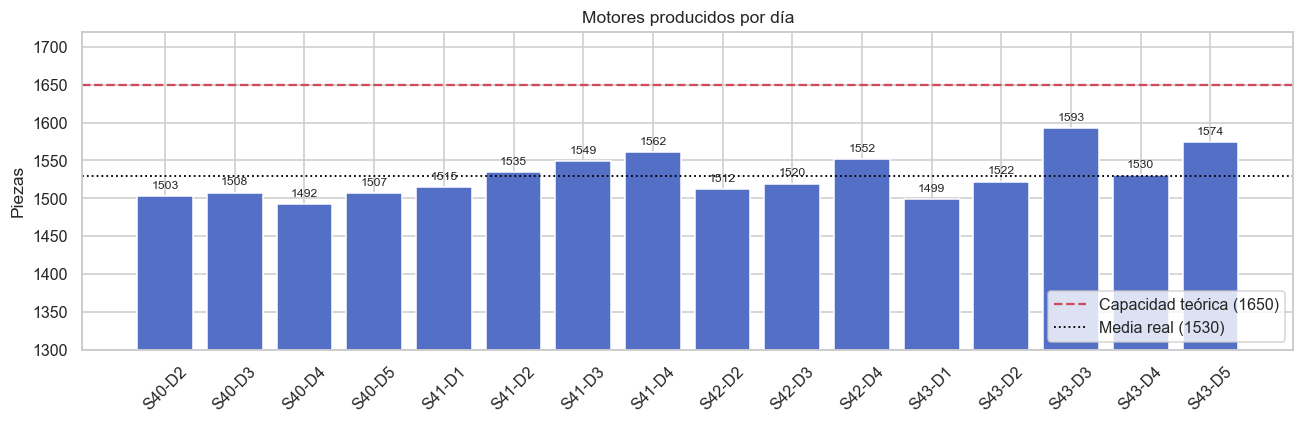

Producción media: 1530 piezas/día -> 92.7 % de la capacidad teórica
Total del periodo: 24.472 motores


In [5]:
fiable_npr = a[~a.Operacion.isin(NPR_NO_FIABLE + PARALELO)]
prod = fiable_npr.groupby(DIA).NPR.median().reset_index()
prod["dia"] = dias
CAPACIDAD = T_ABIERTO * 6000 / TCY_OBJ

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(prod.dia, prod.NPR, color="#5470C6")
ax.axhline(CAPACIDAD, color="#D1495B", ls="--", lw=1.5, label=f"Capacidad teórica ({CAPACIDAD:.0f})")
ax.axhline(prod.NPR.mean(), color="black", ls=":", lw=1.2, label=f"Media real ({prod.NPR.mean():.0f})")
for x, y in zip(prod.dia, prod.NPR):
    ax.text(x, y + 10, f"{y:.0f}", ha="center", fontsize=8)
ax.set(title="Motores producidos por día", ylabel="Piezas", ylim=(1300, 1720))
ax.tick_params(axis="x", rotation=45); ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

print(f"Producción media: {prod.NPR.mean():.0f} piezas/día -> {100 * prod.NPR.mean() / CAPACIDAD:.1f} % de la capacidad teórica")
print(f"Total del periodo: {prod.NPR.sum():,.0f} motores".replace(",", "."))

**Qué vemos:**
- La línea es **muy estable**: produce entre ~1490 y ~1590 motores al día, sin días catastróficos.
- Trabaja a un **~93 % de su capacidad teórica**. Se pierden unos 120 motores al día. Ese margen es lo que se puede recuperar atacando la máquina crítica.
- La última semana (S43) es algo mejor que las primeras.

### 2.2 ¿En qué se le va el tiempo a la línea?

Sumamos las horas de todas las máquinas y todos los días y vemos el reparto.

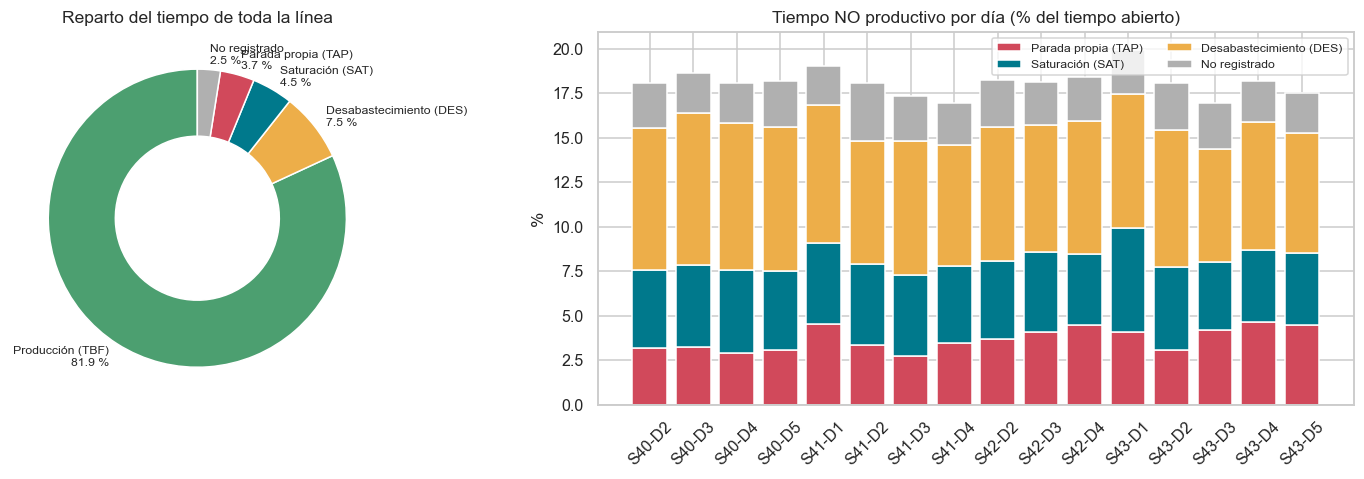

TBF                81.9
TAP                 3.7
DES                 7.5
SAT                 4.5
T_no_registrado     2.5
dtype: float64

In [6]:
tot = a[ESTADOS + ["T_no_registrado"]].sum()
tot_pct = 100 * tot / tot.sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})
orden = ["TBF", "DES", "SAT", "TAP", "T_no_registrado"]
ax1.pie(tot_pct[orden], labels=[f"{NOMBRES[k]}\n{tot_pct[k]:.1f} %" for k in orden],
        colors=[COLORES[k] for k in orden], startangle=90, wedgeprops={"width": 0.45, "edgecolor": "white"},
        textprops={"fontsize": 8})
ax1.set_title("Reparto del tiempo de toda la línea")

evo = a.groupby(DIA)[ESTADOS + ["T_no_registrado"]].sum()
evo = 100 * evo.div(evo.sum(axis=1), axis=0)
evo.index = dias
abajo = np.zeros(len(evo))
for k in ["TAP", "SAT", "DES", "T_no_registrado"]:
    ax2.bar(evo.index, evo[k], bottom=abajo, color=COLORES[k], label=NOMBRES[k])
    abajo += evo[k].values
ax2.set(title="Tiempo NO productivo por día (% del tiempo abierto)", ylabel="%")
ax2.tick_params(axis="x", rotation=45); ax2.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()
tot_pct.round(1)

**Qué vemos:**
- Las máquinas producen un **~82 %** del tiempo.
- La **parada inducida (DES + SAT ≈ 12 %) es más de 3 veces la parada propia (TAP ≈ 3,7 %)**. Esta es la conclusión más importante del EDA:

> **La línea pierde mucho más tiempo esperando (máquinas sanas frenadas por otras) que por averías.** Por eso no basta con mirar quién falla más: hay que encontrar **qué máquina provoca esas esperas**.

- Entre las inducidas domina el **desabastecimiento (DES)**: muchas máquinas se quedan sin piezas, lo que apunta a restricciones **en la parte inicial o media** de la línea.
- El reparto es muy parecido todos los días: la línea tiene un comportamiento **estructural**, no de días puntuales.

*(Nota: la TAP global está algo inflada por ST_2235, cuyo sensor de paradas es defectuoso.)*

## 3. Indicadores de HORSE por máquina

| Indicador | Fórmula | Qué mide | Referencia |
|---|---|---|---|
| **Dp** (disponibilidad propia) | TBF / (TBF + TAP) | De su tiempo activo, cuánto produce sin fallar | **≥ 90 %** |
| **Tcy** (tiempo de ciclo) | TBF × 6000 / NPR (cmin por pieza) | Cuánto tarda en hacer una pieza cuando funciona | **≤ 80 cmin** |
| **Fpm** (fallos por mil) | NAP / NPR × 1000 | Paradas propias por cada 1000 piezas | Cuanto menos, mejor |
| **MTTR** | TAP / NAP (minutos) | Duración media de una parada propia | — |
| **MTBF** | TBF / NAP (horas) | Tiempo medio produciendo entre dos paradas | — |

Dp y MTTR/MTBF se calculan solo si la TAP es fiable; Tcy y Fpm, solo si las piezas son fiables.

In [7]:
op["Dp"] = 100 * op.TBF / (op.TBF + op.TAP)
op["Tcy"] = op.TBF * 6000 / op.NPR.replace(0, np.nan)
op["Fpm"] = 1000 * op.NAP / op.NPR.replace(0, np.nan)
op["MTTR_min"] = 60 * op.TAP / op.NAP.replace(0, np.nan)
op["MTBF_h"] = op.TBF / op.NAP.replace(0, np.nan)
op.loc[~op.tap_fiable, ["Dp", "MTTR_min", "MTBF_h"]] = np.nan
op.loc[~op.npr_fiable, ["Tcy", "Fpm"]] = np.nan
# En puestos en paralelo cada uno hace la mitad de piezas: su Tcy efectivo para la línea es la mitad
op["Tcy_efectivo"] = np.where(op.Operacion.isin(PARALELO), op.Tcy / 2, op.Tcy)

op[["Operacion_norm", "Dp", "Tcy", "Tcy_efectivo", "Fpm", "MTTR_min", "MTBF_h"]].describe().round(1)

,Dp,Tcy,Tcy_efectivo,Fpm,MTTR_min,MTBF_h
count,84.0,82.0,82.0,82.0,84.0,84.0
mean,96.4,73.8,71.9,50.9,0.9,6.4
std,8.2,15.8,8.3,85.8,1.0,34.2
min,33.1,19.6,19.6,0.0,0.0,0.0
25%,96.6,69.5,69.5,12.0,0.4,0.3
50%,98.4,74.0,74.0,25.8,0.7,0.5
75%,99.1,76.3,76.2,50.2,1.1,1.1
max,100.0,165.4,82.7,571.3,7.4,303.8


### 3.1 Disponibilidad (Dp ≥ 90 %)

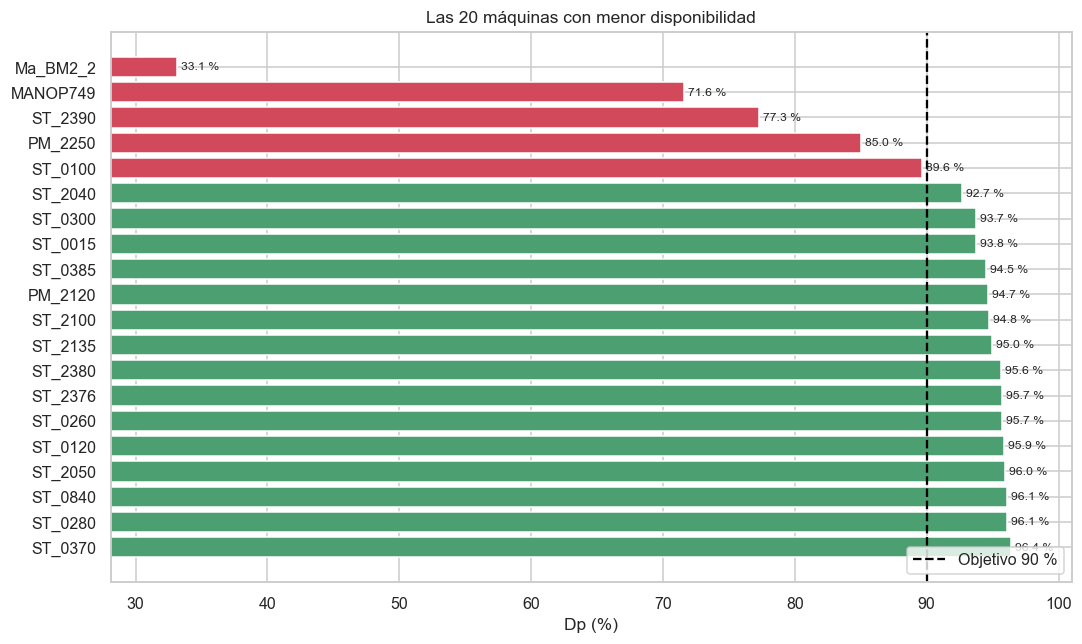

Por debajo del 90 %: ['ST_0100', 'PM_2250', 'ST_2390', 'Ma_BM2_2', 'MANOP749']
Por encima del 90 %: 79 de 84 máquinas


In [8]:
dp = op.dropna(subset=["Dp"]).sort_values("Dp").head(20)
fig, ax = plt.subplots(figsize=(10, 6))
col = np.where(dp.Dp < DP_OBJ, "#D1495B", "#4C9F70")
ax.barh(dp.Operacion_norm, dp.Dp, color=col)
ax.axvline(DP_OBJ, color="black", ls="--", label="Objetivo 90 %")
for y, v in enumerate(dp.Dp):
    ax.text(v + 0.3, y, f"{v:.1f} %", va="center", fontsize=8)
ax.set(title="Las 20 máquinas con menor disponibilidad", xlabel="Dp (%)", xlim=(min(30, dp.Dp.min() - 5), 101))
ax.invert_yaxis(); ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

print("Por debajo del 90 %:", op.loc[op.Dp < DP_OBJ, "Operacion_norm"].tolist())
print(f"Por encima del 90 %: {(op.Dp >= DP_OBJ).sum()} de {op.Dp.notna().sum()} máquinas")

- **Casi todas las máquinas cumplen** el 90 %. La fiabilidad propia de la línea es buena.
- Por debajo del objetivo están **MANOP749, ST_2390, PM_2250, ST_0100** y, sobre todo, **Ma_BM2_2**.
  - Ma_BM2_2 es un elemento de manutención con días de parada completa sospechosos (está en las alertas): su Dp es poco creíble.
  - MANOP749 y PM_2250 están muy influidas por averías puntuales muy largas (también en las alertas).
- **ST_2390** es el caso más interesante: Dp del 77 % con muchas paradas. Es la candidata clara a **problema de fiabilidad**.

### 3.2 Tiempo de ciclo (Tcy ≤ 80 cmin)

El tiempo de ciclo indica **lo rápida que es cada máquina cuando funciona**. Una máquina con Tcy alto va justa de capacidad: cualquier parada suya se nota en la línea. Es un candidato natural a **cuello de botella**.

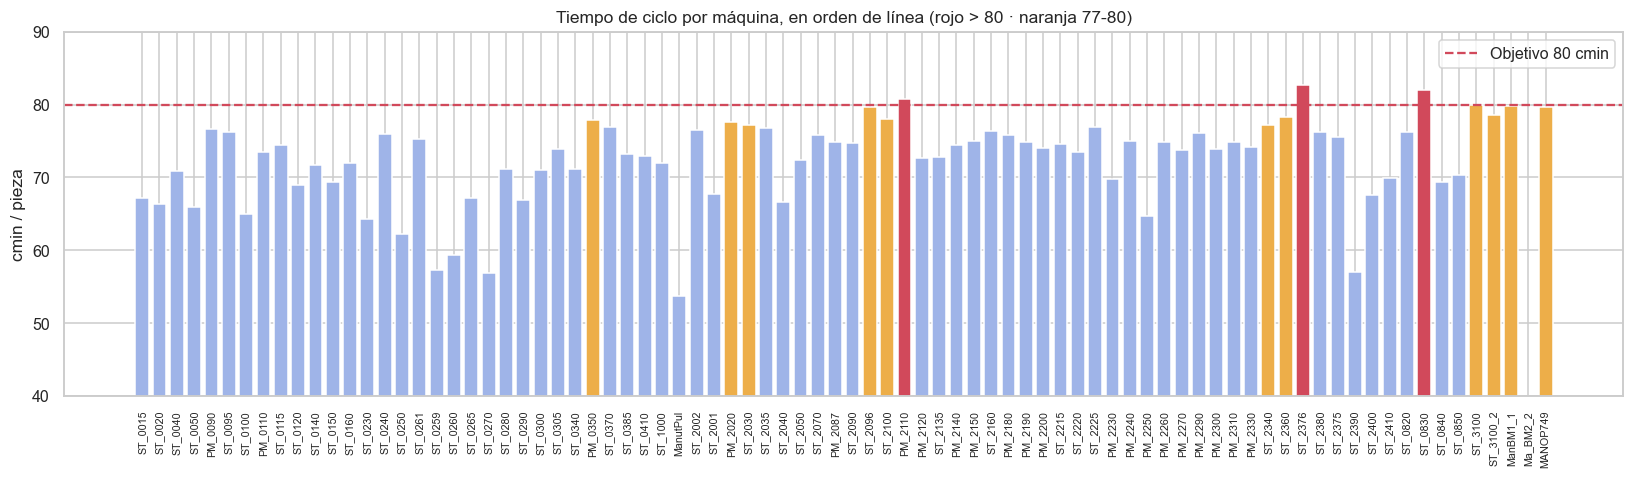

,Orden_OP,Operacion_norm,Tcy,Tcy_efectivo,pct_TBF,pct_TAI
69,72,ST_2376,165.4,82.7,91.9,3.9
76,79,ST_0830,82.0,82.0,95.0,3.7
45,47,PM_2110,80.8,80.8,91.4,5.8
79,82,ST_3100,79.9,79.9,92.0,6.0
82,85,ManBM1_1,79.8,79.8,92.2,6.7
43,45,ST_2096,79.7,79.7,91.2,7.5
84,91,MANOP749,79.7,79.7,55.3,21.4
80,83,ST_3100_2,78.6,78.6,90.4,8.9
68,71,ST_2360,78.3,78.3,90.9,6.7
44,46,ST_2100,78.1,78.1,89.7,5.2


In [9]:
tc = op.dropna(subset=["Tcy_efectivo"]).sort_values("Orden_OP")
fig, ax = plt.subplots(figsize=(15, 4.5))
col = np.where(tc.Tcy_efectivo > TCY_OBJ, "#D1495B", np.where(tc.Tcy_efectivo > 77, "#EDAE49", "#9FB4E8"))
ax.bar(tc.Operacion_norm, tc.Tcy_efectivo, color=col)
ax.axhline(TCY_OBJ, color="#D1495B", ls="--", lw=1.5, label="Objetivo 80 cmin")
ax.set(title="Tiempo de ciclo por máquina, en orden de línea (rojo > 80 · naranja 77-80)", ylabel="cmin / pieza", ylim=(40, 90))
ax.tick_params(axis="x", rotation=90, labelsize=7); ax.legend(); plt.tight_layout(); plt.show()

tc.sort_values("Tcy_efectivo", ascending=False)[["Orden_OP", "Operacion_norm", "Tcy", "Tcy_efectivo", "pct_TBF", "pct_TAI"]].head(10).round(1)

- La mayoría de máquinas están entre **65 y 80 cmin**, por debajo del objetivo.
- Las más **justas de ciclo** (más cerca de 80 o por encima) son **ST_2376 (en paralelo), ST_0830, PM_2110, ST_3100, ManBM1_1, ST_2096, ST_3100_2, ST_2360**. Casi todas están en la **parte final** de la línea.
- ⚠️ Ojo con la interpretación: un Tcy alto puede ser porque la máquina **es lenta** o porque **trabaja "a medio gas"** (se cuenta como TBF el tiempo entre piezas). Fíjate que las máquinas con Tcy alto también tienen **muy poca TAI**: casi nunca esperan. Es justo el perfil de un cuello de botella.
- Los puestos en paralelo (ST_2376 y ST_2375) tienen un Tcy de ~150-165 cmin, pero como se reparten las piezas su Tcy efectivo para la línea es la mitad (~75-83).

### 3.3 ¿Cómo para cada máquina? Frecuencia frente a duración

Dos máquinas con la misma TAP pueden necesitar soluciones muy distintas:
- **Muchas paradas cortas** (Fpm alto, MTTR bajo): microparadas, ajustes, atascos. Se atacan con mejora continua o ingeniería.
- **Pocas paradas largas** (Fpm bajo, MTTR alto): averías serias. Se atacan con mantenimiento.

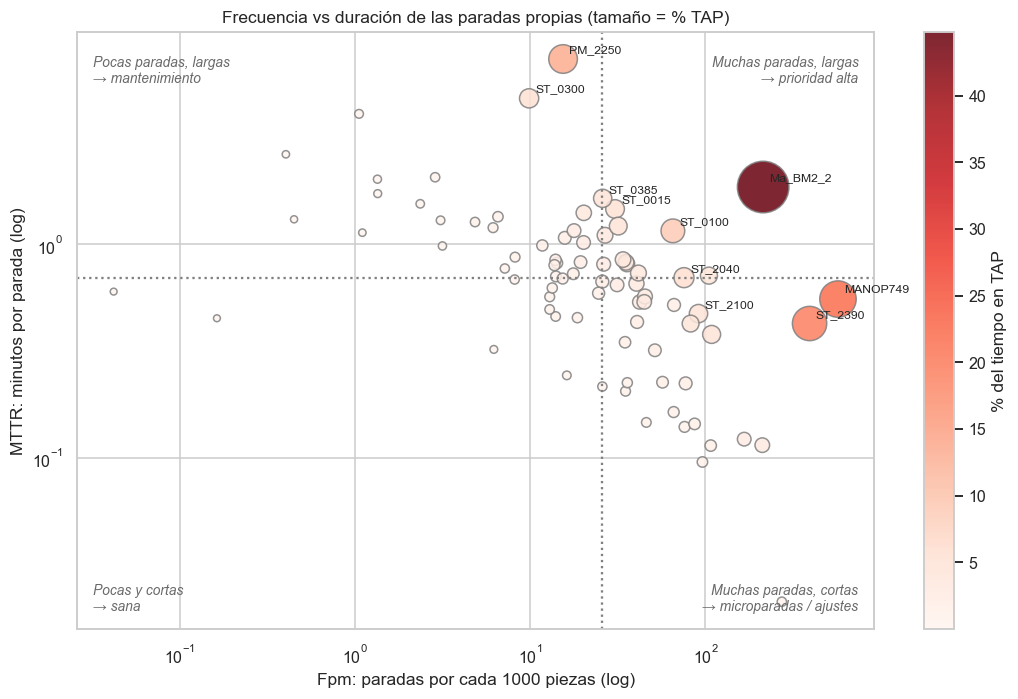

In [10]:
fm = op.dropna(subset=["Fpm", "MTTR_min"])
fm = fm[(fm.NAP > 0)]
fig, ax = plt.subplots(figsize=(10, 6.5))
tam = 20 + 25 * fm.pct_TAP
sc = ax.scatter(fm.Fpm, fm.MTTR_min, s=tam, c=fm.pct_TAP, cmap="Reds", edgecolor="grey", alpha=0.85)
ax.set_xscale("log"); ax.set_yscale("log")
ax.axvline(fm.Fpm.median(), color="grey", ls=":"); ax.axhline(fm.MTTR_min.median(), color="grey", ls=":")
for _, r in fm.nlargest(10, "pct_TAP").iterrows():
    ax.annotate(r.Operacion_norm, (r.Fpm, r.MTTR_min), fontsize=8, xytext=(4, 4), textcoords="offset points")
kw = dict(transform=ax.transAxes, fontsize=9, color="dimgray", style="italic")
ax.text(0.02, 0.96, "Pocas paradas, largas\n→ mantenimiento", va="top", **kw)
ax.text(0.98, 0.96, "Muchas paradas, largas\n→ prioridad alta", va="top", ha="right", **kw)
ax.text(0.98, 0.03, "Muchas paradas, cortas\n→ microparadas / ajustes", ha="right", **kw)
ax.text(0.02, 0.03, "Pocas y cortas\n→ sana", **kw)
plt.colorbar(sc, label="% del tiempo en TAP")
ax.set(title="Frecuencia vs duración de las paradas propias (tamaño = % TAP)",
       xlabel="Fpm: paradas por cada 1000 piezas (log)", ylabel="MTTR: minutos por parada (log)")
plt.tight_layout(); plt.show()

- La mayoría de máquinas tienen paradas **cortas, de alrededor de 1 minuto** (MTTR bajo): la TAP de la línea son sobre todo **microparadas**.
- **ST_2390** es la que tiene más paradas por pieza (~390 por cada mil piezas) y la mayor TAP fiable: es un problema de **microparadas muy frecuentes**.
- **PM_2250, ST_0300 y PM_2310** tienen pocas paradas pero muy largas (de 4 a 7 min): ahí el perfil es de **averías**.
- Los puestos manuales (PM_0090, PM_0110…) tienen muchísimas paradas de segundos. Lo más probable es que sean **pulsaciones o esperas del operario** registradas como parada, más que averías.

## 4. Paradas propias (TAP): quién falla más

### 4.1 Ranking de TAP: el método "ingenuo"

Es lo que se haría a mano: ordenar las máquinas por horas de parada propia. Lo calculamos para **compararlo después** con el resultado de los métodos de cuello de botella.

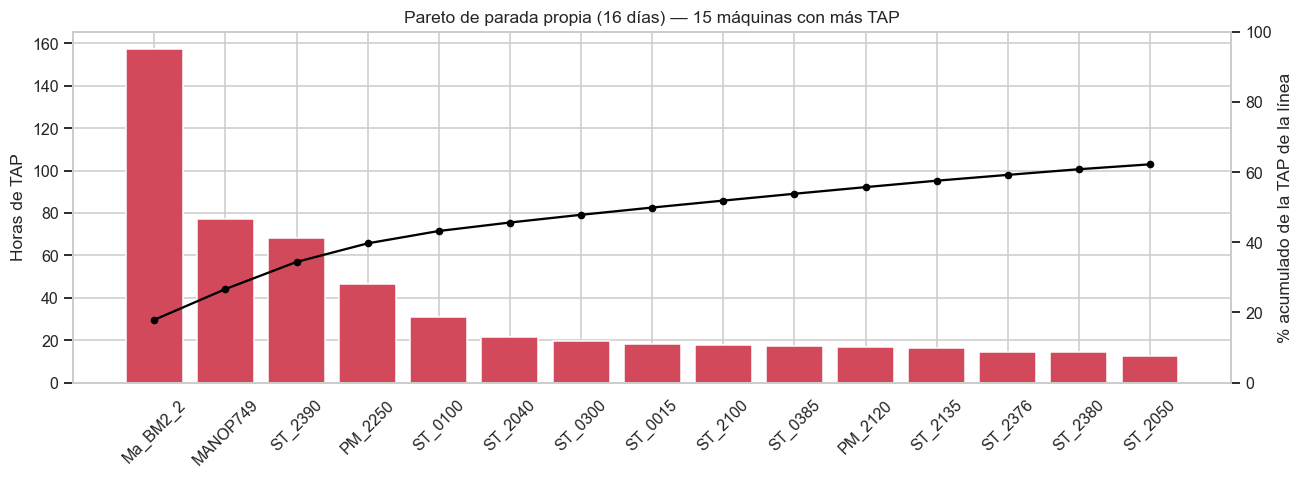

,Operacion_norm,TAP,pct_TAP,NAP,acum
83,Ma_BM2_2,157.6,44.8,5099,17.9
84,MANOP749,77.3,22.0,8376,26.6
72,ST_2390,68.3,19.4,9630,34.4
60,PM_2250,46.6,13.2,379,39.7
6,ST_0100,31.1,8.8,1613,43.2
38,ST_2040,21.3,6.1,1834,45.6
24,ST_0300,19.4,5.5,241,47.8
0,ST_0015,18.2,5.2,747,49.9
44,ST_2100,17.5,5.0,2218,51.9
29,ST_0385,17.2,4.9,628,53.8


In [11]:
rk = op[op.tap_fiable].sort_values("TAP", ascending=False).head(15).copy()
rk["acum"] = 100 * rk.TAP.cumsum() / op.loc[op.tap_fiable, "TAP"].sum()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(rk.Operacion_norm, rk.TAP, color=COLORES["TAP"])
ax.set(title="Pareto de parada propia (16 días) — 15 máquinas con más TAP", ylabel="Horas de TAP")
ax.tick_params(axis="x", rotation=45)
ax2 = ax.twinx(); ax2.plot(rk.Operacion_norm, rk.acum, color="black", marker="o", ms=4)
ax2.set_ylabel("% acumulado de la TAP de la línea"); ax2.set_ylim(0, 100); ax2.grid(False)
plt.tight_layout(); plt.show()
rk[["Operacion_norm", "TAP", "pct_TAP", "NAP", "acum"]].round(1)

- Unas pocas máquinas concentran buena parte de la TAP: **Ma_BM2_2, ST_2390, MANOP749, PM_2250, ST_0100**…
- Pero según la teoría **esto no dice cuál es la máquina crítica**. Que una máquina pare mucho no significa que frene a la línea: depende de si las demás la están esperando.

### 4.2 ¿Paradas de siempre o de días puntuales?

Mapa de calor de la TAP de las 25 máquinas que más paran, día a día. Una fila **uniforme** indica un problema **crónico**; una fila con **un único punto oscuro**, una avería **puntual**.

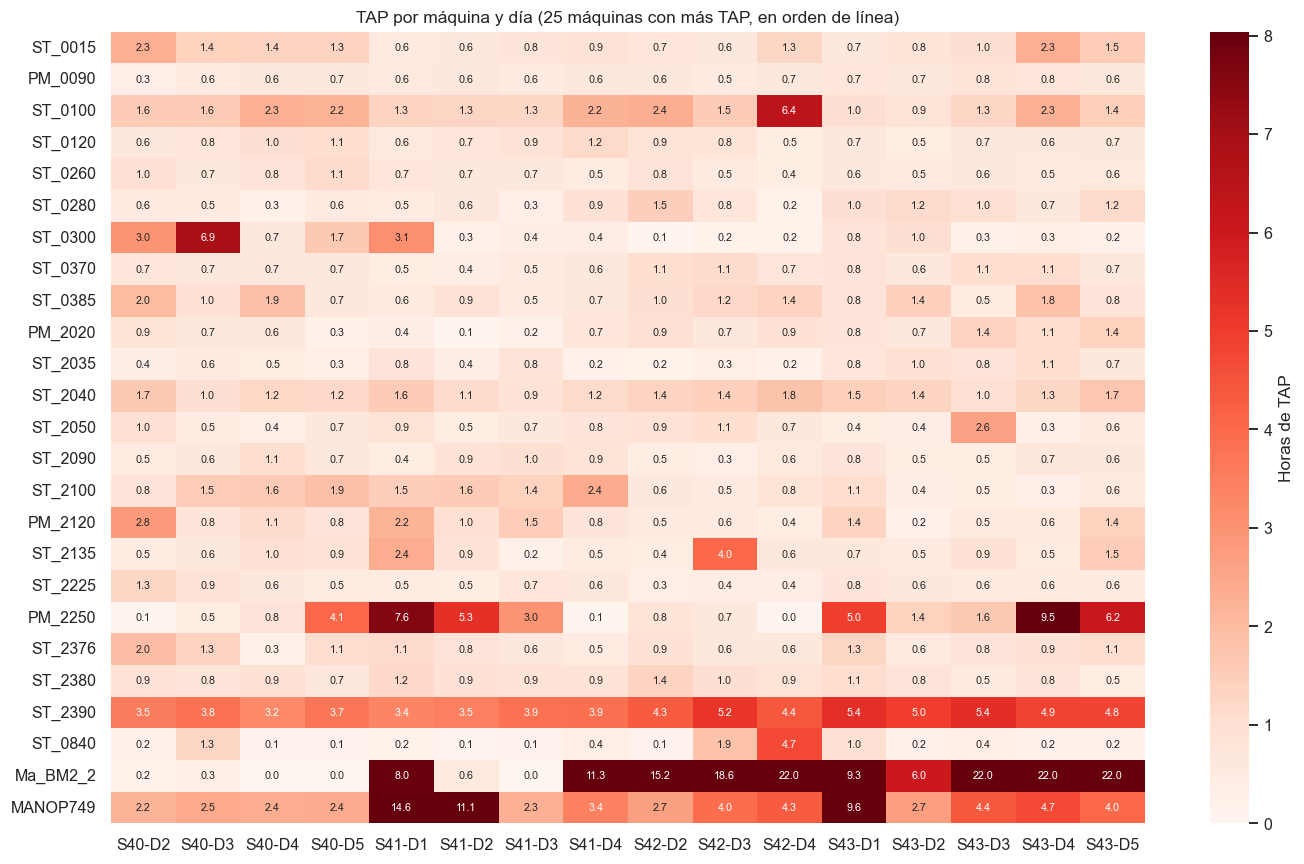

In [12]:
top = op[op.tap_fiable].nlargest(25, "TAP").sort_values("Orden_OP").Operacion_norm
hm = a[a.Operacion_norm.isin(top)].pivot_table(index="Operacion_norm", columns="dia", values="TAP")[dias].reindex(top)
fig, ax = plt.subplots(figsize=(13, 8))
sns.heatmap(hm, cmap="Reds", annot=True, fmt=".1f", annot_kws={"size": 7}, cbar_kws={"label": "Horas de TAP"}, ax=ax,
            vmax=np.nanpercentile(hm.values, 97))
ax.set(title="TAP por máquina y día (25 máquinas con más TAP, en orden de línea)", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

- **ST_2390** para todos los días (de ~2 a 7 h): es un problema **crónico**.
- **MANOP749, PM_2250, ST_0300, ST_0100** tienen sobre todo **picos puntuales**: averías de un día concreto que inflan su total.
- **Ma_BM2_2** combina días de 22 h (sospechosos, ver alertas) con días normales.

Distinguir lo crónico de lo puntual es clave para el jefe de línea: lo crónico pide un plan de mejora y lo puntual un análisis de esa avería.

## 5. Paradas inducidas a lo largo de la línea

Aquí está la información que más nos interesa. Recordamos la teoría:
- **SAT** se propaga **hacia atrás** desde la máquina que frena: las anteriores se bloquean.
- **DES** se propaga **hacia delante**: las posteriores se quedan sin piezas.

Si dibujamos SAT y DES de cada máquina **en orden de línea**, alrededor de una máquina crítica debería verse **SAT alta antes, DES alto después, y ella con poca TAI**.

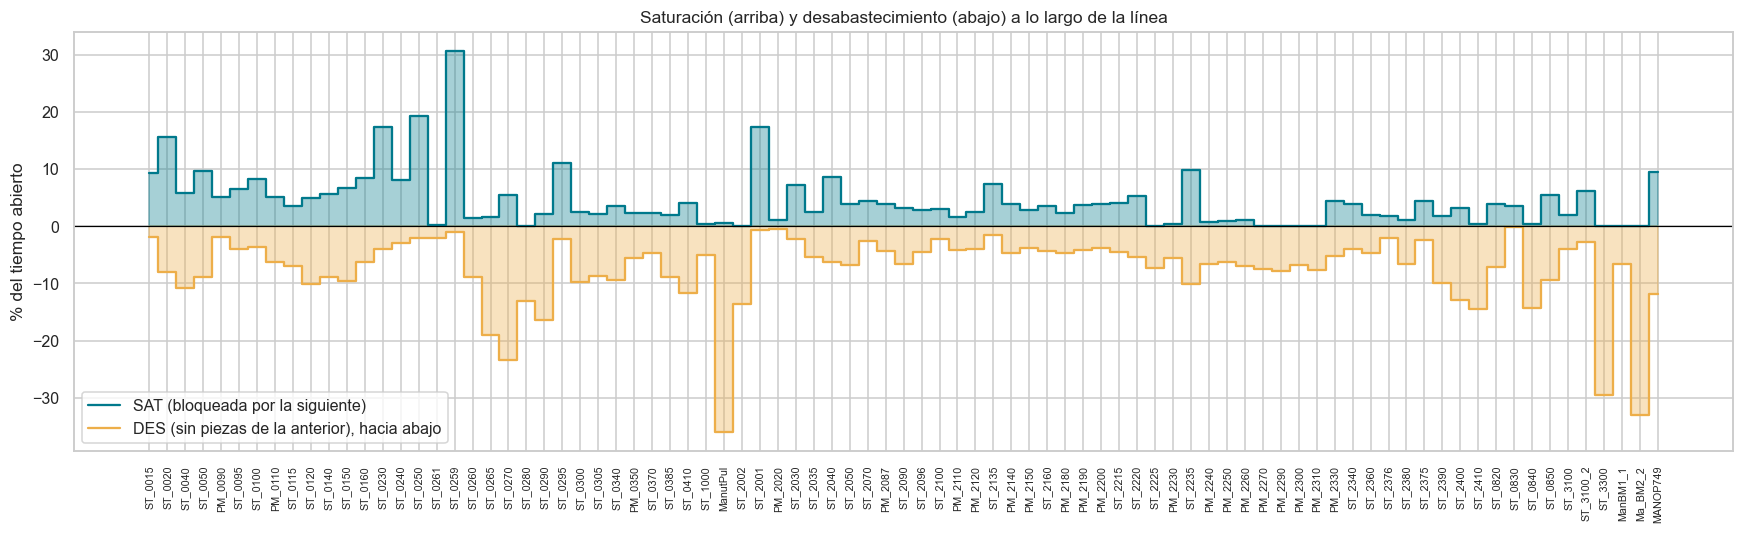

In [13]:
fig, ax = plt.subplots(figsize=(16, 5))
x = np.arange(len(op))
ax.fill_between(x, op.pct_SAT, color=COLORES["SAT"], alpha=0.35, step="mid")
ax.plot(x, op.pct_SAT, color=COLORES["SAT"], lw=1.5, drawstyle="steps-mid", label="SAT (bloqueada por la siguiente)")
ax.fill_between(x, -op.pct_DES, color=COLORES["DES"], alpha=0.35, step="mid")
ax.plot(x, -op.pct_DES, color=COLORES["DES"], lw=1.5, drawstyle="steps-mid", label="DES (sin piezas de la anterior), hacia abajo")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x, op.Operacion_norm, rotation=90, fontsize=7)
ax.set(title="Saturación (arriba) y desabastecimiento (abajo) a lo largo de la línea", ylabel="% del tiempo abierto")
ax.legend(loc="lower left"); plt.tight_layout(); plt.show()

**Cómo leerlo:** buscamos los puntos donde se pasa de **SAT alta (arriba)** a **DES alto (abajo)**. Ahí está la frontera entre "las que esperan para soltar" y "las que esperan para recibir", que es donde suele estar la máquina que frena.

**Qué vemos:**
- **Tramo inicial (ST_0015 → ST_0259):** dominan las **SAT altas**, con picos en ST_0230, ST_0250 y sobre todo **ST_0259 (31 % de SAT)**. Estas máquinas están bloqueadas: algo **por delante** de ellas va más lento.
- **Justo después (ST_0261, ST_0260, ST_0265, ST_0270…):** la SAT cae a casi 0 y aparece un **DES fuerte** (hasta ~23 % en ST_0270). Esa frontera alrededor de **ST_0259 / ST_0261 / ST_0260** es la **primera pista clara de cuello de botella**.
- **ManutPul** tiene un 36 % de DES: es una manutención que pasa mucho tiempo esperando piezas, seguida de ST_2002 (DES) y ST_2001 (SAT).
- En la **parte final** (bloques PM_22xx-23xx, ST_24xx, ST_08xx) domina otra vez el **DES**. Las máquinas de ese tramo esperan piezas, y eso coincide con que las máquinas de **Tcy alto y poca TAI** (ST_0830, ST_3100) están en esa zona.
- El perfil tiene **varias fronteras**, no una sola: es una línea larga (85 máquinas) y probablemente con **varios cuellos de botella locales**, separados por buffers.

### 5.1 Perfil del "punto de inflexión": D = SAT − DES

Para cada máquina, D > 0 indica que predomina la saturación (el problema está delante) y D < 0 que predomina el desabastecimiento (el problema está detrás). Los **cambios de signo de + a −** marcan los candidatos a cuello de botella. Suavizamos con una media móvil de 3 para no reaccionar al ruido de una sola máquina.

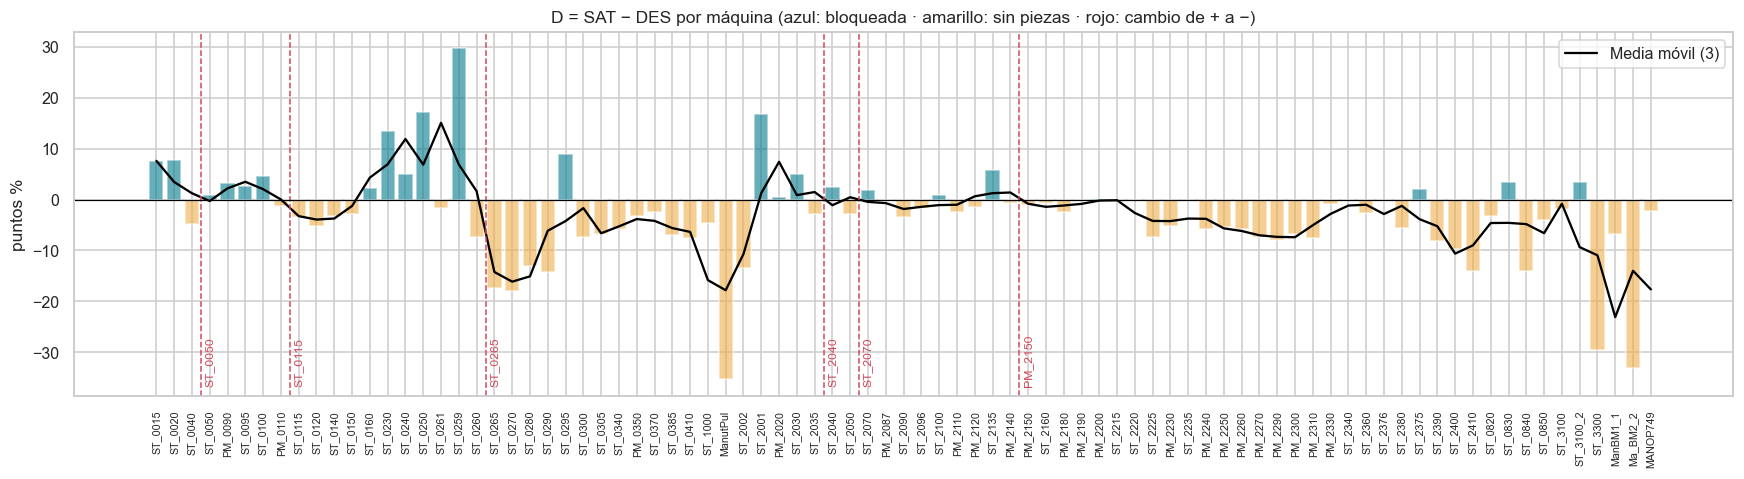

Cambios de signo (candidatos): ['ST_0050', 'ST_0115', 'ST_0265', 'ST_2040', 'ST_2070', 'PM_2150']


In [14]:
op["D"] = op.pct_SAT - op.pct_DES
op["D_suave"] = op.D.rolling(3, center=True, min_periods=1).mean()
cambios = [i for i in range(1, len(op)) if op.D_suave.iloc[i - 1] > 0 and op.D_suave.iloc[i] <= 0]

fig, ax = plt.subplots(figsize=(16, 4.5))
ax.bar(x, op.D, color=np.where(op.D > 0, COLORES["SAT"], COLORES["DES"]), alpha=0.6)
ax.plot(x, op.D_suave, color="black", lw=1.5, label="Media móvil (3)")
for i in cambios:
    ax.axvline(i - 0.5, color="#D1495B", ls="--", lw=1)
    ax.text(i - 0.3, 0.03, op.Operacion_norm.iloc[i], rotation=90, fontsize=8, color="#D1495B",
            transform=ax.get_xaxis_transform())
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x, op.Operacion_norm, rotation=90, fontsize=7)
ax.set(title="D = SAT − DES por máquina (azul: bloqueada · amarillo: sin piezas · rojo: cambio de + a −)", ylabel="puntos %")
ax.legend(); plt.tight_layout(); plt.show()
print("Cambios de signo (candidatos):", [op.Operacion_norm.iloc[i] for i in cambios])

- El cambio **más marcado** de toda la línea está en el tramo **ST_0259 → ST_0260 / ST_0265**: se pasa de **+30 puntos** (ST_0259, muy bloqueada) a **−17** (ST_0265, sin piezas). Entre medias está **ST_0261**, con D ≈ 0: ni la bloquean ni la dejan sin piezas.
- Un segundo cambio claro está en **ST_2001 (+17) → PM_2020 → ST_2030**. **PM_2020** queda justo en la frontera.
- El resto de cambios (ST_0050, ST_0115, ST_2070, PM_2150) son suaves, de unos pocos puntos: probablemente ruido o restricciones menores.
- En la parte final de la línea D es negativo casi siempre (todo desabastecimiento). Encaja con que las restricciones principales estén **antes**.

Esto es solo una **exploración**. En el siguiente notebook aplicaremos los métodos completos (TAI mínima, flechas con índice de severidad y punto de inflexión) para obtener el ranking de máquinas críticas.

### 5.2 TAI frente a TAP: quién frena y quién es frenada

Cruzamos las dos dimensiones de cada máquina:
- **Eje X: TAI** (cuánto la frenan las demás).
- **Eje Y: TAP** (cuánto falla ella).

La teoría dice que el **cuello de botella** está **a la izquierda** (casi nunca espera a nadie). Si además tiene TAP alta, cada fallo suyo se nota en toda la línea.

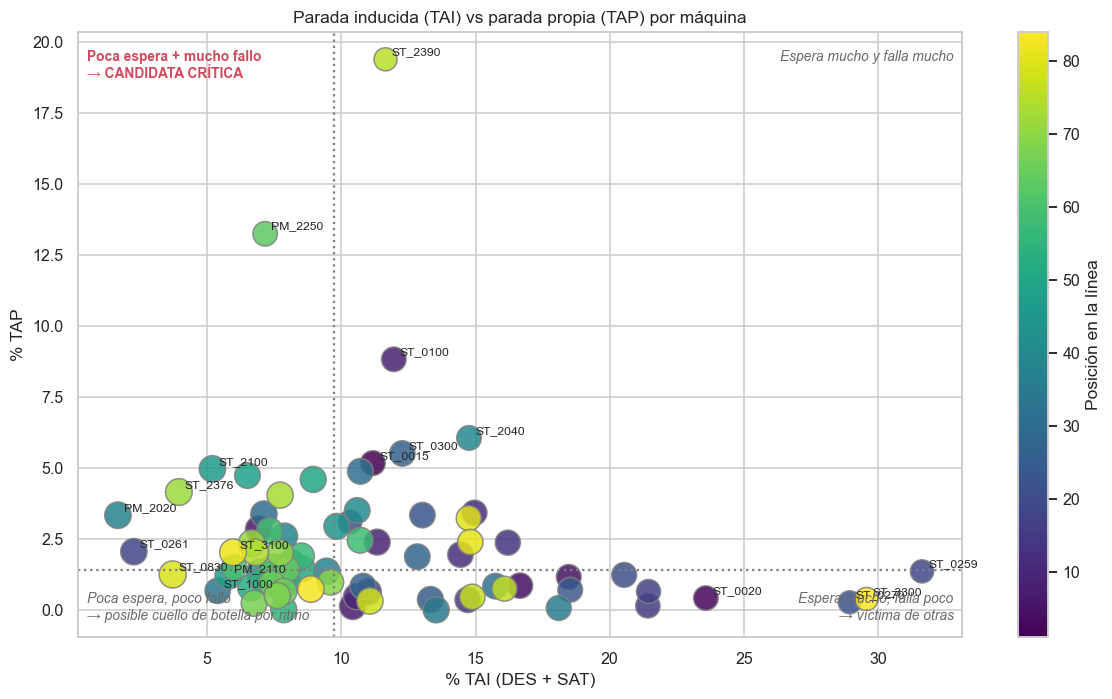

In [15]:
sub = op[op.tap_fiable & (op.Tipo != "Manutención / auxiliar")]
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.scatter(sub.pct_TAI, sub.pct_TAP, s=30 + 3 * sub.pct_TBF, c=sub.Orden_OP, cmap="viridis", edgecolor="grey", alpha=0.85)
ax.axvline(sub.pct_TAI.median(), color="grey", ls=":"); ax.axhline(sub.pct_TAP.median(), color="grey", ls=":")
etiquetar = pd.concat([sub.nsmallest(8, "pct_TAI"), sub.nlargest(6, "pct_TAP"), sub.nlargest(4, "pct_TAI")]).drop_duplicates()
for _, r in etiquetar.iterrows():
    ax.annotate(r.Operacion_norm, (r.pct_TAI, r.pct_TAP), fontsize=8, xytext=(4, 3), textcoords="offset points")
kw = dict(transform=ax.transAxes, fontsize=9, color="dimgray", style="italic")
ax.text(0.01, 0.97, "Poca espera + mucho fallo\n→ CANDIDATA CRÍTICA", va="top", color="#D1495B", fontsize=9, transform=ax.transAxes, weight="bold")
ax.text(0.99, 0.97, "Espera mucho y falla mucho", va="top", ha="right", **kw)
ax.text(0.01, 0.03, "Poca espera, poco fallo\n→ posible cuello de botella por ritmo", **kw)
ax.text(0.99, 0.03, "Espera mucho, falla poco\n→ víctima de otras", ha="right", **kw)
sm = plt.cm.ScalarMappable(cmap="viridis", norm=plt.Normalize(sub.Orden_OP.min(), sub.Orden_OP.max()))
plt.colorbar(sm, ax=ax, label="Posición en la línea")
ax.set(title="Parada inducida (TAI) vs parada propia (TAP) por máquina", xlabel="% TAI (DES + SAT)", ylabel="% TAP")
plt.tight_layout(); plt.show()

- **Abajo a la derecha** están las **víctimas**: máquinas que casi no fallan pero pasan mucho tiempo esperando (ST_0259, ST_0270, ST_0020, ST_0230, ST_0250). Arreglarlas **no** mejoraría la línea.
- **A la izquierda** (TAI muy baja) están las que **casi nunca esperan**: **PM_2020 (1,7 %), ST_0261 (2,3 %), ST_0830, ST_2376, ST_2100, ST_1000**. Son las candidatas a cuello de botella.
  - **ST_0261** encaja con el perfil de SAT/DES: está justo en la frontera más marcada. Antes tiene a ST_0259 con un 31 % de SAT y después máquinas con mucho DES.
  - **PM_2020** es la que menos espera de toda la línea **y además tiene un 3,3 % de TAP**. Está en la frontera ST_2001 (17 % SAT) → ST_2030. Es el perfil de "candidata crítica": cada fallo suyo frena a sus vecinas.
- **ST_2390** tiene la mayor TAP fiable, pero también un 12 % de TAI: falla mucho, pero también espera. Habrá que ver con los métodos si es crítica o no.

## 6. ¿Es siempre la misma máquina? Variación día a día

Aplicamos la idea más simple (la máquina con **menor TAI** del día) a cada día por separado. Así vemos si el cuello de botella es **estable o móvil**.

⚠️ **Efecto borde:** las máquinas al principio o al final de la línea, y las de manutención, pueden tener poca TAI solo por su posición (no tienen nadie delante o detrás que las frene). Por eso las excluimos de este ranking.

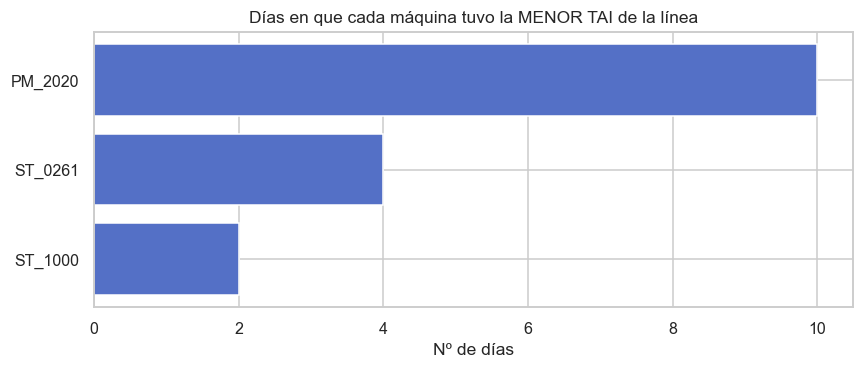

,1ª (menor TAI),2ª,3ª
dia,,,
S40-D2,ST_0261,PM_2020,ST_0830
S40-D3,ST_0261,PM_2020,ST_1000
S40-D4,ST_0261,PM_2020,ST_0830
S40-D5,PM_2020,ST_0261,ST_0830
S41-D1,ST_1000,ST_0261,PM_2020
S41-D2,PM_2020,ST_0261,ST_1000
S41-D3,ST_1000,PM_2020,ST_0261
S41-D4,ST_0261,PM_2020,ST_0830
S42-D2,PM_2020,ST_0261,ST_2376


In [16]:
cand = a[(a.Tipo != "Manutención / auxiliar") & ~a.Operacion.isin(TAP_NO_FIABLE)]
primera, ultima = cand.Orden_OP.min(), cand.Orden_OP.max()
cand = cand[~cand.Orden_OP.isin([primera, ultima])]

top3 = (cand.sort_values("TAI").groupby(DIA).head(3)
            .assign(puesto=lambda x: x.groupby(DIA).cumcount() + 1))
piv = top3.pivot_table(index="dia", columns="puesto", values="Operacion_norm", aggfunc="first").reindex(dias)
piv.columns = ["1ª (menor TAI)", "2ª", "3ª"]

cuenta = top3[top3.puesto == 1].Operacion_norm.value_counts()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(cuenta.index, cuenta.values, color="#5470C6"); ax.invert_yaxis()
ax.set(title="Días en que cada máquina tuvo la MENOR TAI de la línea", xlabel="Nº de días")
plt.tight_layout(); plt.show()
piv

- **PM_2020** tiene la menor TAI en **10 de los 16 días**, **ST_0261** en 4 y **ST_1000** en 2. El podio diario se reparte siempre entre estas y ST_0830 / ST_2376.
- En la **semana 43**, ST_2376 entra en el podio todos los días: merece seguimiento.
- Eso indica un **cuello de botella bastante estable** (estructural) más que móvil. Para HORSE es una buena noticia: **merece la pena una actuación de fondo** sobre esas máquinas, en lugar de "apagar fuegos" día a día.

### 6.1 Evolución de las candidatas

Seguimos día a día el % de tiempo produciendo y la TAI de las candidatas detectadas. Un cuello de botella "de verdad" tiene **TBF alto y TAI baja de forma sostenida**.

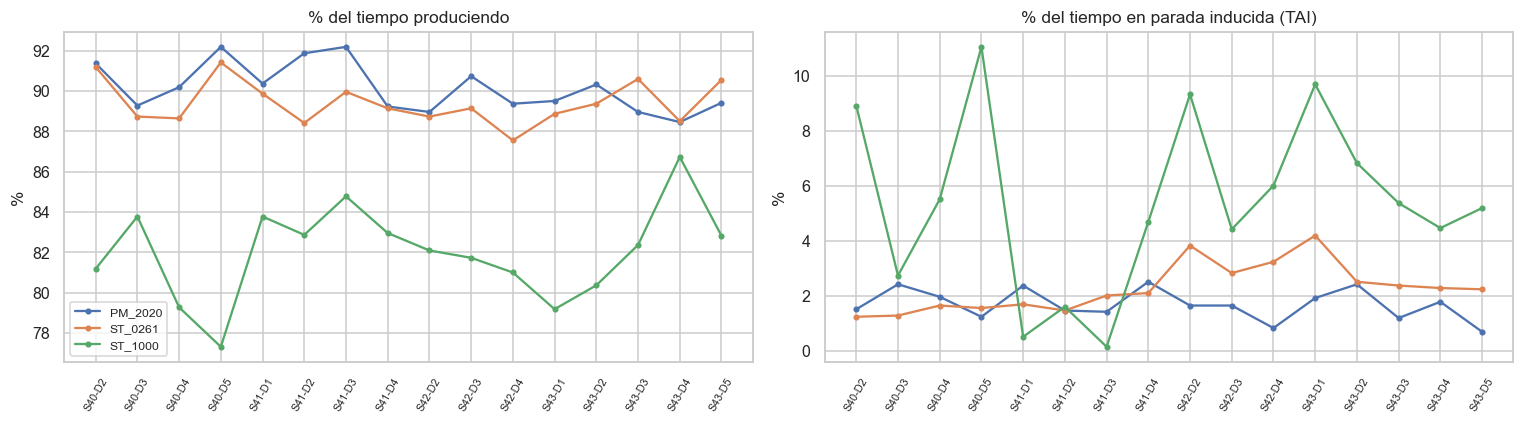

In [17]:
candidatas = cuenta.index[:4].tolist()
ev = a[a.Operacion_norm.isin(candidatas)].pivot_table(index="dia", columns="Operacion_norm", values=["pct_TBF", "pct_TAI"]).reindex(dias)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4), sharex=True)
for m in candidatas:
    ax1.plot(dias, ev[("pct_TBF", m)], marker="o", ms=3, label=m)
    ax2.plot(dias, ev[("pct_TAI", m)], marker="o", ms=3, label=m)
ax1.set(title="% del tiempo produciendo", ylabel="%"); ax2.set(title="% del tiempo en parada inducida (TAI)", ylabel="%")
for ax_ in (ax1, ax2):
    ax_.tick_params(axis="x", rotation=60, labelsize=7)
ax1.legend(fontsize=8); plt.tight_layout(); plt.show()

## 7. Conclusiones del EDA

**Sobre la línea**
1. Produce **~1530 motores/día**, un **~93 % de su capacidad teórica** (1650). Es muy **estable**: no hay días catastróficos.
2. **Pierde más de 3 veces más tiempo en paradas inducidas (12 %) que en paradas propias (3,7 %).** El problema no es que las máquinas se averíen, sino que **se frenan unas a otras**. Esto justifica el enfoque del reto.

**Sobre los indicadores**
3. **Disponibilidad:** casi todas superan el 90 %. Las que no (ST_2390, PM_2250, ST_0100, MANOP749) lo hacen por microparadas crónicas (ST_2390) o por averías puntuales.
4. **Tiempo de ciclo:** todas rondan los 65-80 cmin. Las más justas (ST_0830, PM_2110, ST_3100…) están al final de la línea y casi nunca esperan.
5. **Tipo de parada:** la mayoría son **microparadas de ~1 min**. ST_2390 destaca por frecuencia y PM_2250, ST_0300 y PM_2310 por duración.

**Sobre la máquina crítica (hipótesis para el siguiente paso)**
6. El método ingenuo (más TAP) señalaría a ST_2390, MANOP749 o PM_2250. **Pero ninguna de ellas tiene el perfil de cuello de botella**, porque también pasan tiempo esperando.
7. El perfil de SAT/DES muestra **dos fronteras claras**, cada una con una máquina que casi nunca espera:
   - **ST_0259 → ST_0261 → ST_0260/0265**: mucha saturación antes y desabastecimiento después. **ST_0261** está en medio, con un 2,3 % de TAI.
   - **ST_2001 → PM_2020 → ST_2030**. **PM_2020** tiene la menor TAI de la línea (1,7 %), es la de menor TAI en 10 de 16 días y además falla (3,3 % de TAP).
8. Hay otras candidatas más débiles: ST_1000, ST_0830 y ST_2376 (en paralelo). La línea probablemente tiene **varios cuellos de botella locales**.
9. El cuello de botella parece **estable** en el periodo: lo que pide son actuaciones de fondo.

**Siguiente paso:** aplicar formalmente los métodos de detección (TAI mínima, flechas con índice de severidad, punto de inflexión) en global y por día, y construir el **ranking de criticidad**.

**Limitaciones a tener en cuenta**
- Las preguntas abiertas de la limpieza: puestos en paralelo, orden de la configuración, límites de la línea.
- Un ~5 % del tiempo de algunas máquinas está sin registrar.
- Solo hay 16 días de datos: las conclusiones por día son orientativas.